# A CNN on Sentinel-2 Images (EuroSAT)

Adapted from the TensorFlow tutorial [Convolutional Neural Network](https://www.tensorflow.org/tutorials/images/cnn), using Sentinel-2 images (EuroSAT) instead of CIFAR-10. The concepts are explained for GIS and remote sensing users with ArcGIS tools: convolution works like Focal Statistics, and max pooling like Aggregate (Maximum).

**Run the cells from top to bottom, in order.**

### 1. Import TensorFlow

In [25]:
import tensorflow as tf
import numpy as np                # to count results by class
import matplotlib.pyplot as plt   # to draw images and graphs

### 2. Load the EuroSAT images

**Before running this cell:** download `EuroSAT_RGB.zip` from [Zenodo](https://zenodo.org/records/7711810) and unzip it into a folder called `eurosat_data`, next to this notebook (or run the download cell of notebook 01).

EuroSAT contains 27,000 Sentinel-2 images, 64 × 64 pixels, with 3 bands (RGB, 8-bit JPG). The images are stored in one folder per class, 
and Keras uses the folder names as labels. 80% of the images are used for training and 20% for testing, in batches of 32. 
Each batch is a tensor of shape (32, 64, 64, 3): a stack of 32 rasters.
The 10 classes are: AnnualCrop, Forest, HerbaceousVegetation, Highway, Industrial, Pasture, PermanentCrop, Residential, River, and SeaLake.

In [8]:
data_dir = "eurosat_data/EuroSAT_RGB" # Downloaded from https://zenodo.org/records/7711810

train_ds, test_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,    # 20% of the images are kept for testing
    subset="both",           # return the training and the test datasets
    seed=42,                 # same split at every run
    image_size=(64, 64),     # EuroSAT images are 64 x 64 pixels
    batch_size=32,           # 32 images per batch
)

print("Classes:", train_ds.class_names)

Found 27000 files belonging to 10 classes.
Using 21600 files for training.
Using 5400 files for validation.
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


### 3. Check the data

Before training, I display 25 images with their labels, to check that they match.

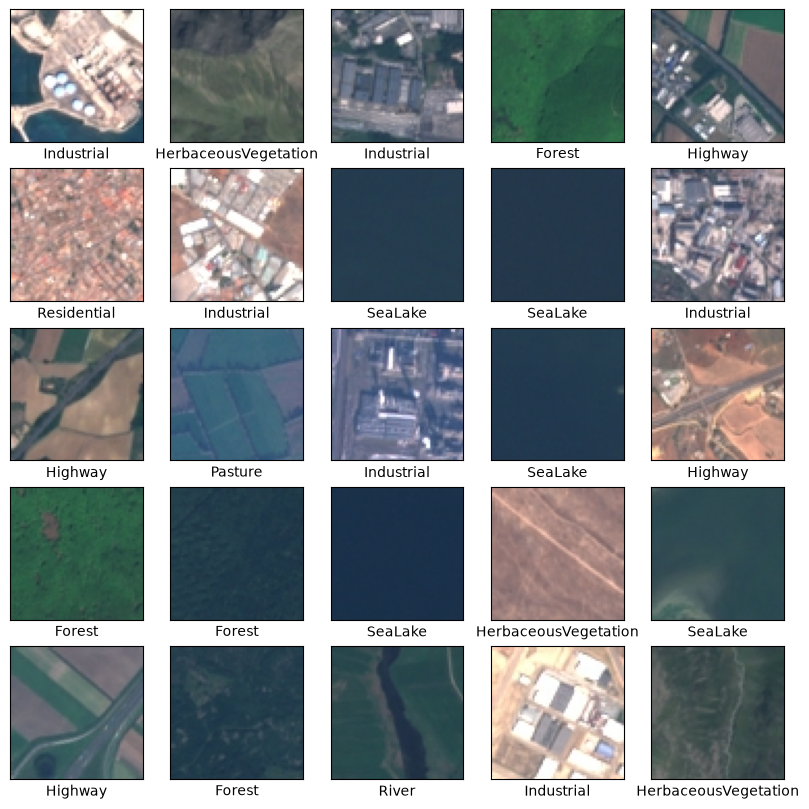

In [15]:
import matplotlib.pyplot as plt

class_names = train_ds.class_names

plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(25):
        plt.subplot(5, 5, i + 1)
        plt.xticks([])     # Delete axis numbers around the images
        plt.yticks([])
        plt.imshow(images[i].numpy().astype("uint8")) # pixel values 0-255
        plt.xlabel(class_names[int(labels[i])])  # class name under the image
plt.show()

### 4. Build the CNN

Convolutional base. Three Conv2D layers find patterns in the image. The first one uses 32 filters of 3 × 3 pixels to find simple patterns, like edges and color changes. Each filter is a window that slides over the image, and the model learns its values. One image becomes 32 maps, like running Focal Statistics 32 times with 32 different kernels and stacking the outputs like bands.

MaxPooling2D keeps the highest value of each 2 × 2 block (62 → 31), like Aggregate with the Maximum technique. The maps get smaller, the strongest signals stay, and the next filters can see a wider area of the original image. The next Conv2D layers (64 filters each) combine the simple patterns into more complex shapes, like a road crossing a field or the curve of a river.

Dense layers. Flatten unrolls the result into one line, Dense(64) combines the shapes, and Dense(10) gives one score per land-cover class.

In [18]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(64, 64, 3)),      # 64 rows, 64 columns, 3 bands
    tf.keras.layers.Rescaling(1.0 / 255), # Models learn better and faster with small numbers. Normalization
# Rescaling(1.0 / 255) divides every value by 255, so they go from 0 to 1

# Convolutional base : find patterns, then shapes
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),   # 32 filters of 3 x 3 -> (62, 62, 32)
    tf.keras.layers.MaxPooling2D((2, 2)),      # keep the max of each 2 x 2 block -> (31, 31, 32)
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),     # 64 filters -> (29, 29, 64)
    tf.keras.layers.MaxPooling2D((2, 2)),     # -> (14, 14, 64) 
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),  # 64 filters -> (12, 12, 64)

# Dense layers: combine the shapes and choose a class
    tf.keras.layers.Flatten(),              # (12, 12, 64) -> one line of 9,216 numbers
    tf.keras.layers.Dense(64, activation="relu"),       # 64 neurons combine the shapes
    tf.keras.layers.Dense(10),              # 10 scores, one per land-cover class
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)                │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 62, 62, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 29, 29, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 12, 12, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 9216)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │         589,888 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 646,858 (2.47 MB)

 Trainable params: 646,858 (2.47 MB)

 Non-trainable params: 0 (0.00 B)

### 5. Compile and train the CNN

The loss measures the mistakes, the Adam optimizer adjusts the weights (including the filters), and accuracy shows the percentage of correct answers.
With validation_data, the model is also tested on the 20% of test images at the end of each epoch (val_accuracy).

In [19]:
model.compile(optimizer="adam",
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=["accuracy"])

# Train for 10 epochs and test on the test images after each epoch
history = model.fit(train_ds, epochs=10, validation_data=test_ds)

Epoch 1/10


675/675 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.4994 - loss: 1.2989 - val_accuracy: 0.6196 - val_loss: 1.0048
Epoch 2/10
675/675 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.6953 - loss: 0.8419 - val_accuracy: 0.7389 - val_loss: 0.7663
Epoch 3/10
675/675 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.7509 - loss: 0.6867 - val_accuracy: 0.7807 - val_loss: 0.5975
Epoch 4/10
675/675 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.7786 - loss: 0.6182 - val_accuracy: 0.7580 - val_loss: 0.7074
Epoch 5/10
675/675 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.8175 - loss: 0.5153 - val_accuracy: 0.7963 - val_loss: 0.5855
Epoch 6/10
675/675 ━━━━━━━━━━━━━━━━━━━━ 12s 18ms/step - accuracy: 0.8348 - loss: 0.4669 - val_accuracy: 0.8050 - val_loss: 0.5533
Epoch 7/10
675/675 ━━━━━━━━━━━━━━━━━━━━ 12s 18ms/step - accuracy: 0.8512 - loss: 0.4141 - val_accuracy: 0.8072 - val_loss: 0.5807
Epoch 8/10
675/675 ━━━━━━━━━━━━━━━━━━━━ 12s 18ms/step - accuracy: 0.8662 - loss: 0.3710 - val_accurac

### 6. Evaluate the model

The graph compares the accuracy on the training images and on the test images after each epoch. 
A growing gap between the two lines means the model starts to memorize the training images (overfitting).

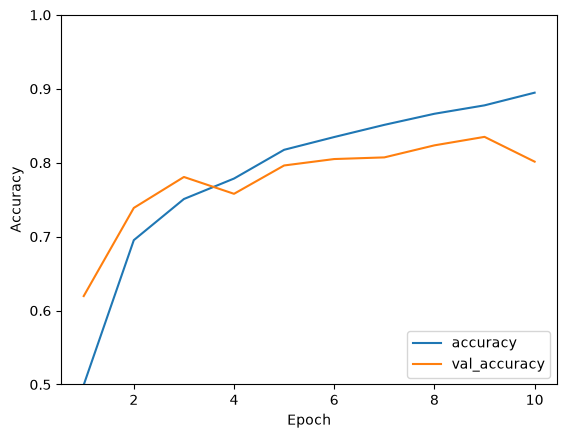

169/169 - 1s - 8ms/step - accuracy: 0.8015 - loss: 0.6522
Test accuracy: 0.8014814853668213


In [22]:
plt.plot(range(1, 11), history.history["accuracy"], label="accuracy")

plt.plot(range(1, 11), history.history["val_accuracy"], label="val_accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.ylim([0.5, 1])
plt.legend(loc="lower right")
plt.show()

test_loss, test_acc = model.evaluate(test_ds, verbose=2)
print("Test accuracy:", test_acc)

On the 5,400 test images, the CNN reached **80% accuracy** (chance: 10%). The best test accuracy was **83.5% at epoch 9**. At epoch 10, the training accuracy kept rising (89%) while the test accuracy dropped (80%): the model started to memorize the training images (overfitting).

### 7. Accuracy by class

For each class, the percentage of test images classified correctly. In ArcGIS terms, this is the producer's accuracy. 

In [28]:
import numpy as np

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0).argmax(axis=1)
    y_true.extend(labels.numpy())
    y_pred.extend(predictions)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Percentage of correct answers for each class
for i, name in enumerate(class_names):
    is_this_class = (y_true == i)
    correct = np.mean(y_pred[is_this_class] == i)
    print(f"{name:22} {correct:.0%}   ({is_this_class.sum()} images)")

AnnualCrop             75%   (597 images)
Forest                 94%   (600 images)
HerbaceousVegetation   67%   (557 images)
Highway                73%   (493 images)
Industrial             97%   (512 images)
Pasture                78%   (374 images)
PermanentCrop          57%   (491 images)
Residential            96%   (607 images)
River                  62%   (547 images)
SeaLake                97%   (622 images)


Water, buildings, and forests are the easiest classes (94–97%), because each has a texture that looks like nothing else. The hardest are PermanentCrop (57%), River (62%), and HerbaceousVegetation (67%): with only red, green, and blue at 10 m, the vegetation classes look very similar. Near-infrared and red-edge bands would help separate them.

### Links

- Article on Medium: *coming soon*
- Previous notebook (a Flatten + Dense model, 47%): [01_tensorflow_first_model](../01_tensorflow_first_model/01_tensorflow_first_model_eurosat.ipynb)
- TensorFlow CNN tutorial: https://www.tensorflow.org/tutorials/images/cnn
- EuroSAT: Helber, P., Bischke, B., Dengel, A., & Borth, D. (2019). EuroSAT: A Novel Dataset and Deep Learning Benchmark for Land Use and Land Cover Classification. *IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing*, 12(7), 2217–2226.